# Final Random Forest: Mass / Volume

One fitted model predicts Structural Mass / Metric Volume [kg/m³] from Height and the existing geometry metrics. SOM towers are external validation only. The fitted 80% training-split model is exported without refitting on the holdout.

Original Section 6 selected its fallback `{"n_estimators": 500, "random_state": 42}`: the earlier dictionary was named `random_forest_settings`, not the name its lookup expected. Defaults therefore include `max_features=1.0` and `n_jobs=None`. These are now explicit; all resolved parameters are also exported.

Corrections: retain Metric Volume when constructing the analysis dataset (previously omitted, preventing a fresh run); exclude raw volume columns by name so Surface-to-Volume Ratio is retained as requested (the old substring filter accidentally removed it); replace the malformed validation column list and label R² correctly. Restoring that feature can change predictions from the old feature-filtered experiment. Dataset cleaning, reciprocal Plan Aspect Ratio, no-setback handling, row order and the 80/20 random split are preserved.

Obsolete three-target preparation/training and direct-mass external experiments have been removed. Sections 4C, 6B, 6C and a second 4E experiment were not present in this version.

## 1. Imports and paths

In [20]:
import csv
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------
# SECTION 1A - CLEAN DATASETS
# ---------------------------------------------------

main_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune"
)

labels_path = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\Labels.csv"
)

resultsSR7_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\SR7\results"
)

resultsSR11_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\SR11\results"
)

resultsSR15_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\SR15\results"
)

surface_areaSR7_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\May23\Data\SR7\SR7surfaceareas"
)

surface_areaSR11_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\May23\Data\SR11\SR11surfaceareas"
)

surface_areaSR15_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\May23\Data\SR15\SR15surfaceareas"
)

prediction_results_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\PredictionModelResults"
)

SAVE_OUTPUTS = False



import joblib
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

## 2. Load and clean SR7 / SR11 / SR15 datasets

In [ ]:
with labels_path.open(newline="", encoding="utf-8-sig") as labels_file:
    labels = next(csv.reader(labels_file))

expected_value_count = len(labels)

duplicate_column_names = sorted([
    column
    for column, count in Counter(labels).items()
    if count > 1
])


def make_unique_columns(columns):
    seen = Counter()
    unique_columns = []

    for column in columns:
        seen[column] += 1
        if seen[column] == 1:
            unique_columns.append(column)
        else:
            unique_columns.append(f"{column}__{seen[column]}")

    return unique_columns


unique_labels = make_unique_columns(labels)


def read_surface_area_value(csv_path):
    if not csv_path.exists():
        return np.nan

    try:
        raw_values = pd.read_csv(csv_path, header=None).to_numpy().ravel()
    except Exception:
        return np.nan

    numeric_values = pd.to_numeric(
        pd.Series(raw_values),
        errors="coerce"
    ).dropna()

    if numeric_values.empty:
        return np.nan

    return float(numeric_values.iloc[0])


def load_single_sr_dataset(sr_label, results_folder, surface_area_folder):
    csv_files = sorted(results_folder.glob("*.csv"))
    rows = []
    failed_files = []

    for file in csv_files:
        try:
            result_data = pd.read_csv(
                file,
                header=None,
                encoding="cp1252"
            )
        except Exception as exc:
            failed_files.append({
                "file": file.name,
                "expected": expected_value_count,
                "actual": f"read error: {exc}",
            })
            continue

        actual_value_count = (
            result_data.shape[1]
            if len(result_data) == 1
            else result_data.size
        )

        if actual_value_count != expected_value_count:
            failed_files.append({
                "file": file.name,
                "expected": expected_value_count,
                "actual": actual_value_count,
            })
            continue

        row = result_data.iloc[0].tolist()
        row.append(file.stem)
        rows.append(row)

    df = pd.DataFrame(
        rows,
        columns=unique_labels + ["Building ID"]
    )

    df["Surface Area"] = df["Building ID"].map(
        lambda building_id: read_surface_area_value(
            surface_area_folder / f"{building_id}.csv"
        )
    )

    df["SR Dataset"] = sr_label

    text_columns = [
        "Building Name",
        "Building ID",
        "Interstory Drift Limit",
        "Analysis Info",
        "SR Dataset",
    ]

    numeric_columns = [
        column
        for column in df.columns
        if column not in text_columns
    ]

    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

    # ---------------------------------------------------
    # SETBACK METRICS FOR BUILDINGS WITH NO SETBACKS
    # ---------------------------------------------------
    # Mean Setback Height and Weighted Mean Setback Height
    # are undefined for buildings with zero setbacks.
    # For these buildings, missing values are represented as 0.

    if "Number of Setbacks" in df.columns:
        no_setbacks = df["Number of Setbacks"] == 0

        setback_height_metrics = [
            "Mean Setback Height",
            "Weighted Mean Setback Height",
        ]

        for column in setback_height_metrics:
            if column in df.columns:
                df.loc[no_setbacks, column] = (
                    df.loc[no_setbacks, column]
                    .fillna(0.0)
                )

    # ---------------------------------------------------
    # PLAN ASPECT RATIO
    # ---------------------------------------------------

    if "Plan Aspect Ratio" in df.columns:
        df["Plan Aspect Ratio"] = (
            pd.to_numeric(
                df["Plan Aspect Ratio"],
                errors="coerce"
            )
            .replace(0, np.nan)
            .rdiv(1.0)
        )

    # ---------------------------------------------------
    # REMOVE INVALID STRUCTURAL MASS RESULTS
    # ---------------------------------------------------

    df = df[
        df["Structural Mass"].notna()
        & (df["Structural Mass"] > 0)
    ].copy()

    # ---------------------------------------------------
    # ADD DERIVED RESPONSE METRICS
    # ---------------------------------------------------

    df["Global Drift Ratio"] = (
        df["Max Displacement"] / df["Height"]
    )

    df["Drift Utilization"] = (
        df["Max Displacement"]
        / (df["Height"] / 500)
    )

    # ---------------------------------------------------
    # COMPATIBILITY COLUMNS
    # ---------------------------------------------------

    if (
        "Metric Volume" not in df.columns
        and "Volume" in df.columns
    ):
        df["Metric Volume"] = df["Volume"]

    if (
        "Setback Count" not in df.columns
        and "Number of Setbacks" in df.columns
    ):
        df["Setback Count"] = df["Number of Setbacks"]

    # ---------------------------------------------------
    # DATASET DIAGNOSTICS
    # ---------------------------------------------------

    diagnostics = {
        "files_found": len(csv_files),
        "files_loaded": len(rows),
        "failed_files": failed_files,
        "shape": df.shape,
        "missing_surface_area": (
            int(df["Surface Area"].isna().sum())
            if "Surface Area" in df.columns
            else None
        ),
    }

    return df, diagnostics


# ---------------------------------------------------
# LOAD SR DATASETS
# ---------------------------------------------------

sr7dataset, sr7_diagnostics = load_single_sr_dataset(
    "SR7",
    resultsSR7_folder,
    surface_areaSR7_folder,
)

sr11dataset, sr11_diagnostics = load_single_sr_dataset(
    "SR11",
    resultsSR11_folder,
    surface_areaSR11_folder,
)

sr15dataset, sr15_diagnostics = load_single_sr_dataset(
    "SR15",
    resultsSR15_folder,
    surface_areaSR15_folder,
)


# ---------------------------------------------------
# COMBINE SR DATASETS
# ---------------------------------------------------

fulldataset = pd.concat(
    [
        sr7dataset,
        sr11dataset,
        sr15dataset,
    ],
    ignore_index=True
)

if (
    "Metric Volume" not in fulldataset.columns
    and "Volume" in fulldataset.columns
):
    fulldataset["Metric Volume"] = fulldataset["Volume"]

if (
    "Setback Count" not in fulldataset.columns
    and "Number of Setbacks" in fulldataset.columns
):
    fulldataset["Setback Count"] = fulldataset["Number of Setbacks"]


# ---------------------------------------------------
# ADD GROUND FLOOR AREA (GFA)
# ---------------------------------------------------

ground_floor_area_folders = {
    "SR7": main_folder / "GroundFloorArea" / "SR7",
    "SR11": main_folder / "GroundFloorArea" / "SR11",
    "SR15": main_folder / "GroundFloorArea" / "SR15",
}


def read_gfa_value(csv_path):
    if not csv_path.exists():
        return np.nan

    try:
        raw_values = pd.read_csv(
            csv_path,
            header=None
        ).to_numpy().ravel()

    except Exception:
        return np.nan

    numeric_values = pd.to_numeric(
        pd.Series(raw_values),
        errors="coerce"
    ).dropna()

    if numeric_values.empty:
        return np.nan

    return float(numeric_values.iloc[0])


def add_gfa_to_dataset(df, gfa_folders):
    df = df.copy()

    df["GFA"] = df.apply(
        lambda row: read_gfa_value(
            gfa_folders[row["SR Dataset"]]
            / f"{row['Building ID']}.csv"
        )
        if row["SR Dataset"] in gfa_folders
        else np.nan,
        axis=1,
    )

    return df


sr7dataset = add_gfa_to_dataset(
    sr7dataset,
    ground_floor_area_folders
)

sr11dataset = add_gfa_to_dataset(
    sr11dataset,
    ground_floor_area_folders
)

sr15dataset = add_gfa_to_dataset(
    sr15dataset,
    ground_floor_area_folders
)


# Rebuild full dataset after adding GFA
fulldataset = pd.concat(
    [
        sr7dataset,
        sr11dataset,
        sr15dataset,
    ],
    ignore_index=True
)


# ---------------------------------------------------
# GFA DIAGNOSTICS
# ---------------------------------------------------

print("\nMissing GFA values by SR Dataset:")

print(
    fulldataset
    .groupby("SR Dataset")["GFA"]
    .apply(
        lambda values: int(values.isna().sum())
    )
    .to_string()
)


# ---------------------------------------------------
# CLEANED DATASETS
# ---------------------------------------------------

cleaned_datasets = {
    "SR7": sr7dataset,
    "SR11": sr11dataset,
    "SR15": sr15dataset,
    "ALL": fulldataset,
}

df_clean = fulldataset.copy()


# ---------------------------------------------------
# DATASET ASSEMBLY DIAGNOSTICS
# ---------------------------------------------------

print(
    "Combined MidJune dataset assembly diagnostics"
)

print(
    "---------------------------------------------"
)

print(
    "Duplicate column names in Labels.csv:",
    duplicate_column_names
    if duplicate_column_names
    else "none"
)

for dataset_label, diagnostics in [
    ("SR7", sr7_diagnostics),
    ("SR11", sr11_diagnostics),
    ("SR15", sr15_diagnostics),
]:

    print(f"\n{dataset_label}")

    print(
        "Files found:",
        diagnostics["files_found"]
    )

    print(
        "Files loaded:",
        diagnostics["files_loaded"]
    )

    print(
        "Failed files:",
        len(diagnostics["failed_files"])
    )

    for failed_file in diagnostics["failed_files"]:
        print(
            f"- {failed_file['file']}: "
            f"expected {failed_file['expected']}, "
            f"actual {failed_file['actual']}"
        )

    print(
        "Dataframe shape:",
        diagnostics["shape"]
    )

    print(
        "Missing Surface Area values:",
        diagnostics["missing_surface_area"]
    )


print(
    "\nFull dataframe shape:",
    fulldataset.shape
)

print(
    "Unique SR Dataset values:",
    sorted(
        fulldataset[
            "SR Dataset"
        ].dropna().unique()
    )
)


# ---------------------------------------------------
# SLENDERNESS RATIO DIAGNOSTICS
# ---------------------------------------------------

print(
    "\nUnique Slenderness Ratio values "
    "by SR Dataset:"
)

if "Slenderness Ratio" in fulldataset.columns:

    slenderness_by_sr = (
        fulldataset
        .assign(
            **{
                "Slenderness Ratio":
                    pd.to_numeric(
                        fulldataset[
                            "Slenderness Ratio"
                        ],
                        errors="coerce"
                    )
            }
        )
        .groupby(
            "SR Dataset"
        )[
            "Slenderness Ratio"
        ]
        .apply(
            lambda values:
                sorted(
                    values
                    .dropna()
                    .unique()
                    .tolist()
                )
        )
    )

    print(
        slenderness_by_sr.to_string()
    )

else:
    print(
        "Slenderness Ratio column "
        "is not available."
    )

## 3. Geometry metrics and analysis dataset

In [ ]:
# ---------------------------------------------------
# SECTION 1B - ANALYSIS DATASETS
# ---------------------------------------------------

geometry_metrics = [
    "Slenderness Ratio",
    "Plan Aspect Ratio",
    "Volumetric Convexity",
    "Surface-to-Volume Ratio",
    "Mean Compactness",
    "Volumetric Symmetry Score",
    "Plan Aspect Ratio Variation",
    "Max CoM",
    "Bulge Factor",
    "Bulge Height Index",
    "Top-to-Base Width Ratio",
    "Max-to-Min Width Ratio",
    "Mean Floor Area Decrease (%)",
    "Mean Floor Area Increase (%)",
    "Number of Setbacks",
    "Mean Setback Magnitude",
    "Mean Setback Height",
    "Weighted Mean Setback Height",
    "Mean Inward Taper (%)",
    "Mean Outward Taper (%)",
    "Taper Sign Change",
    "Facade Verticality Ratio",
]

performance_metrics = [
    "Structural Mass",
    "Max Base Shear",
    "Max Overturning Moment",
    "Max Interstory Drift Ratio",
]


def create_analysis_dataset(cleaned_dataset):
    analysis_source_df = cleaned_dataset.copy()

    # Remove twist buildings
    twist_mask = pd.Series(False, index=analysis_source_df.index)

    for twist_column in ["Building Name", "Building ID"]:
        if twist_column in analysis_source_df.columns:
            twist_mask |= (
                analysis_source_df[twist_column]
                .astype(str)
                .str.contains("twist", case=False, na=False)
            )

    analysis_source_df = analysis_source_df.loc[~twist_mask].copy()

    # Select available geometry and performance metrics
    selected_geometry_metrics = [
        col for col in geometry_metrics
        if col in analysis_source_df.columns
    ]

    selected_performance_metrics = [
        col for col in performance_metrics
        if col in analysis_source_df.columns
    ]

    # Keep identifiers and relevant variables
    identifier_columns = [
        col for col in [
            "Building ID",
            "Building Name",
            "Variant",
            "Height",
            "Surface Area",
        "Metric Volume",  # Bug fix: needed for the target, never a model input.
            "SR Dataset",
        ]
        if col in analysis_source_df.columns
    ]

    analysis_columns = (
        identifier_columns
        + selected_geometry_metrics
        + selected_performance_metrics
    )

    return analysis_source_df[analysis_columns].copy()


analysis_sr7dataset = create_analysis_dataset(sr7dataset)
analysis_sr11dataset = create_analysis_dataset(sr11dataset)
analysis_sr15dataset = create_analysis_dataset(sr15dataset)
analysis_fulldataset = create_analysis_dataset(fulldataset)

## 4. External SOM validation data

In [ ]:
# ---------------------------------------------------
# EXTERNAL SOM VALIDATION DATA
# ---------------------------------------------------

external_test_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\SOM"
)

external_labels = [
    "Building Name",
    "Height",
    "Volume",
    "Structural Mass",
    "Displacement Limit",
    "Max Displacement",
    "Displacement WYP",
    "Displacement WYN",
    "Displacement WXP",
    "Displacement WXN",
    "Displacement G",
    "Max DEnergy",
    "DEnergy WYP",
    "DEnergy WYN",
    "DEnergy WXP",
    "DEnergy WXN",
    "DEnergy G",
    "Max Base Shear",
    "Max Overturning Moment",
    "Max Interstory Drift Ratio",
    "Interstory Drift Limit",
    "Average Thickness",
    "Metric Height",
    "Metric Volume",
    "Slenderness Ratio",
    "Plan Aspect Ratio",
    "Volumetric Convexity",
    "Surface-to-Volume Ratio",
    "Mean Compactness",
    "Volumetric Symmetry Score",
    "Plan Aspect Ratio Variation",
    "Max CoM",
    "Bulge Factor",
    "Bulge Height Index",
    "Top-to-Base Width Ratio",
    "Max-to-Min Width Ratio",
    "Mean Floor Area Decrease (%)",
    "Mean Floor Area Increase (%)",
    "Number of Setbacks",
    "Mean Setback Magnitude",
    "Mean Setback Height",
    "Weighted Mean Setback Height",
    "Mean Inward Taper (%)",
    "Mean Outward Taper (%)",
    "Taper Sign Change",
    "Twist Ratio",
    "Facade Verticality Ratio",
    "Analysis Info",
]

external_test_rows = []
external_test_building_ids = []

for file in sorted(external_test_folder.glob("*.csv")):
    row = pd.read_csv(
        file,
        header=None,
        encoding="cp1252"
    ).iloc[0].tolist()

    if len(row) != len(external_labels):
        raise ValueError(
            f"{file.name}: expected {len(external_labels)} values using external labels, "
            f"but got {len(row)} values."
        )

    external_test_rows.append(row)
    external_test_building_ids.append(file.stem)

external_test_df = pd.DataFrame(
    external_test_rows,
    columns=external_labels
)
external_test_df["Building ID"] = external_test_building_ids
external_test_df["Variant"] = np.nan

# ---------------------------------------------------
# ADD GROUND FLOOR AREA (GFA) TO EXTERNAL TEST BUILDINGS
# ---------------------------------------------------

external_gfa_folder = Path(
    r"C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\GroundFloorArea\SOM"
)


def read_gfa_value(csv_path):
    if not csv_path.exists():
        return np.nan

    try:
        raw_values = pd.read_csv(csv_path, header=None).to_numpy().ravel()
    except Exception:
        return np.nan

    numeric_values = pd.to_numeric(pd.Series(raw_values), errors="coerce").dropna()

    if numeric_values.empty:
        return np.nan

    return float(numeric_values.iloc[0])


external_test_df["GFA"] = external_test_df["Building ID"].map(
    lambda building_id: read_gfa_value(external_gfa_folder / f"{building_id}.csv")
)

print("Missing external GFA values:", int(external_test_df["GFA"].isna().sum()))

if "Setback Count" not in external_test_df.columns and "Number of Setbacks" in external_test_df.columns:
    external_test_df["Setback Count"] = external_test_df["Number of Setbacks"]

external_text_columns = [
    "Building Name",
    "Building ID",
    "Interstory Drift Limit",
    "Analysis Info",
    "Variant",
]

for column in external_test_df.columns:
    if column not in external_text_columns:
        external_test_df[column] = pd.to_numeric(
            external_test_df[column],
            errors="coerce"
        )

if "Plan Aspect Ratio" in external_test_df.columns:
    external_test_df["Plan Aspect Ratio"] = (
        pd.to_numeric(external_test_df["Plan Aspect Ratio"], errors="coerce")
        .replace(0, np.nan)
        .rdiv(1.0)
    )

if "Setback Count" in external_test_df.columns:
    external_non_setback_mask = (
        pd.to_numeric(
            external_test_df["Setback Count"],
            errors="coerce"
        ).fillna(0)
        == 0
    )
    for setback_height_column in ["Mean Setback Height", "Weighted Mean Setback Height"]:
        if setback_height_column in external_test_df.columns:
            external_test_df.loc[
                external_non_setback_mask
                & external_test_df[setback_height_column].isna(),
                setback_height_column
            ] = 1.0
print("External test buildings loaded:", len(external_test_df))
print("External test dataframe shape:", external_test_df.shape)
print("External labels count:", len(external_labels))
print("Variant present:", "Variant" in external_test_df.columns)
print("Metric Height present:", "Metric Height" in external_test_df.columns)
print("Metric Volume present:", "Metric Volume" in external_test_df.columns)

Missing external GFA values: 0
External test buildings loaded: 4
External test dataframe shape: (4, 52)
External labels count: 48
Variant present: True
Metric Height present: True
Metric Volume present: True


## 5. Final ordered model features

In [ ]:
# Exact raw-volume/response exclusions preserve geometry ratios.
# Bug fix: the old substring exclusion also removed Surface-to-Volume Ratio.
excluded_features = {
    "Metric Volume", "Volume", "Building Volume", "Total Volume", "Metric Height",
    "Structural Mass", "Max Base Shear", "Max Overturning Moment",
    "Max Interstory Drift Ratio", "Mass / Volume",
    *performance_metrics,
}
model_feature_columns = ["Height", *[
    metric for metric in geometry_metrics
    if metric != "Height" and metric in analysis_fulldataset.columns
    and metric not in excluded_features
    and not metric.lower().startswith("height-corrected")
]]
assert model_feature_columns.count("Height") == 1
assert "Slenderness Ratio" in model_feature_columns
assert len(model_feature_columns) == len(set(model_feature_columns))
assert not excluded_features.intersection(model_feature_columns)
assert "Metric Volume" not in model_feature_columns
assert "Volume" not in model_feature_columns
assert "Structural Mass" not in model_feature_columns
if "Plan Aspect Ratio" in analysis_fulldataset.columns:
    assert "Plan Aspect Ratio" in model_feature_columns
print("Final model features:\n")
for index, feature in enumerate(model_feature_columns, start=1):
    print(f"{index}. {feature}")

Final model features:

1. Height
2. Slenderness Ratio
3. Plan Aspect Ratio
4. Volumetric Convexity
5. Surface-to-Volume Ratio
6. Mean Compactness
7. Volumetric Symmetry Score
8. Plan Aspect Ratio Variation
9. Max CoM
10. Bulge Factor
11. Bulge Height Index
12. Top-to-Base Width Ratio
13. Max-to-Min Width Ratio
14. Mean Floor Area Decrease (%)
15. Mean Floor Area Increase (%)
16. Number of Setbacks
17. Mean Setback Magnitude
18. Mean Setback Height
19. Weighted Mean Setback Height
20. Mean Inward Taper (%)
21. Mean Outward Taper (%)
22. Taper Sign Change
23. Facade Verticality Ratio


## 6. Prepare Mass / Volume training data

In [ ]:
model_source_df = analysis_fulldataset.copy()

assert set(model_source_df["SR Dataset"]).issubset({"SR7", "SR11", "SR15"})
assert not set(model_source_df["Building ID"]).intersection(
    external_test_df["Building ID"]
)

required_columns = [
    "Structural Mass",
    "Metric Volume",
    *model_feature_columns,
]

missing_columns = [
    column
    for column in required_columns
    if column not in model_source_df
]

if missing_columns:
    raise KeyError(f"Missing training columns: {missing_columns}")

model_training_df = model_source_df[required_columns].apply(
    pd.to_numeric,
    errors="coerce",
)

model_training_df = model_training_df.replace(
    [np.inf, -np.inf],
    np.nan,
)

model_training_df = model_training_df.loc[
    model_training_df["Metric Volume"] > 0
]

# ---------------------------------------------------
# DIAGNOSTIC: SHOW WHY ROWS WILL BE REMOVED
# ---------------------------------------------------

print("\nMissing values before filtering:")

missing_summary = (
    model_training_df[required_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(missing_summary[missing_summary > 0])

print(
    f"\nRows before removing missing values: "
    f"{len(model_training_df)}"
)

rows_with_missing_values = (
    model_training_df[required_columns]
    .isna()
    .any(axis=1)
    .sum()
)

print(
    f"Rows containing at least one missing value: "
    f"{rows_with_missing_values}"
)

# ---------------------------------------------------
# REMOVE INCOMPLETE ROWS
# ---------------------------------------------------

model_training_df = model_training_df.dropna(
    subset=required_columns
).copy()

model_training_df["Mass / Volume"] = (
    model_training_df["Structural Mass"]
    / model_training_df["Metric Volume"]
)

model_training_df = model_training_df.replace(
    [np.inf, -np.inf],
    np.nan,
).dropna(
    subset=[*required_columns, "Mass / Volume"]
)

if model_training_df.empty:
    raise ValueError("No valid training rows remain.")

X = model_training_df[model_feature_columns].copy()
y = model_training_df["Mass / Volume"].copy()

print(
    f"\nEligible rows: "
    f"{len(model_training_df)} / {len(model_source_df)}"
)


Missing values before filtering:
Series([], dtype: int64)

Rows before removing missing values: 4095
Rows containing at least one missing value: 0

Eligible rows: 4095 / 4095


## 7. Train the final Random Forest

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42,
)
# Original Section 6 took its 500-tree / seed-42 fallback, not the earlier
# experiment's sqrt-feature settings. Make the relevant defaults explicit.
model_settings = {
    "n_estimators": 500,
    "random_state": 42,
    "max_features": 1.0,
    "n_jobs": None,
}
structural_mass_model = RandomForestRegressor(**model_settings)
structural_mass_model.fit(X_train, y_train)
assert list(structural_mass_model.feature_names_in_) == model_feature_columns
print(f"Fitted rows: {len(X_train)}; held-out rows: {len(X_test)}")
print("Random Forest settings:", structural_mass_model.get_params())

Fitted rows: 3276; held-out rows: 819
Random Forest settings: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 500, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


## 8. Internal validation

In [ ]:
def validation_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    nonzero = actual != 0
    return {
        "R²": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": (100 * np.mean(np.abs(
            (predicted[nonzero] - actual[nonzero]) / actual[nonzero]
        ))) if nonzero.any() else np.nan,
    }

predicted_mass_per_volume = structural_mass_model.predict(X_test)
actual_mass_per_volume = y_test
actual_metric_volume = model_training_df.loc[X_test.index, "Metric Volume"]
actual_structural_mass = model_training_df.loc[X_test.index, "Structural Mass"]
predicted_structural_mass = predicted_mass_per_volume * actual_metric_volume
internal_mass_per_volume_metrics = validation_metrics(actual_mass_per_volume, predicted_mass_per_volume)
mass_per_volume_r2 = internal_mass_per_volume_metrics["R²"]
mass_per_volume_mae = internal_mass_per_volume_metrics["MAE"]
mass_per_volume_rmse = internal_mass_per_volume_metrics["RMSE"]
mass_per_volume_mape = internal_mass_per_volume_metrics["MAPE (%)"]
internal_total_mass_metrics = validation_metrics(actual_structural_mass, predicted_structural_mass)
internal_results = pd.DataFrame({
    "Building ID": model_source_df.loc[X_test.index, "Building ID"],
    "SR Dataset": model_source_df.loc[X_test.index, "SR Dataset"],
    "Metric Volume": actual_metric_volume,
    "Actual Mass / Volume": actual_mass_per_volume,
    "Predicted Mass / Volume": predicted_mass_per_volume,
    "Actual Structural Mass": actual_structural_mass,
    "Predicted Structural Mass": predicted_structural_mass,
})
# Bug fix: explicit metric keys replace the old concatenated column names.
display(pd.DataFrame([
    {"Validation": "Internal Mass / Volume", **internal_mass_per_volume_metrics},
    {"Validation": "Internal Total Structural Mass", **internal_total_mass_metrics},
]))

,Validation,R²,MAE,RMSE,MAPE (%)
0,Internal Mass / Volume,0.984731,3.686062e+00,8.594925e+00,0.864347
1,Internal Total Structural Mass,0.984731,1.094760e+06,2.552693e+06,0.864347


## 9. External SOM validation — same fitted model

In [ ]:
missing_features = [feature for feature in model_feature_columns if feature not in external_test_df]
if missing_features:
    raise KeyError(f"Missing external model features: {missing_features}")
external_required_columns = [*model_feature_columns, "Metric Volume", "Structural Mass"]
external_values = external_test_df[external_required_columns].apply(
    pd.to_numeric, errors="coerce"
).replace([np.inf, -np.inf], np.nan)
if external_values.empty or external_values.isna().any().any():
    raise ValueError(f"Invalid external validation values: {external_values.isna().sum().to_dict()}")
if (external_values["Metric Volume"] <= 0).any():
    raise ValueError("External Metric Volume must be positive.")
external_test_df[external_required_columns] = external_values
external_X = external_test_df[model_feature_columns].copy()
external_predicted_mass_per_volume = structural_mass_model.predict(external_X)
external_actual_mass_per_volume = external_test_df["Structural Mass"] / external_test_df["Metric Volume"]
external_predicted_structural_mass = external_predicted_mass_per_volume * external_test_df["Metric Volume"]
external_mass_per_volume_metrics = validation_metrics(
    external_actual_mass_per_volume, external_predicted_mass_per_volume
)
external_total_mass_metrics = validation_metrics(
    external_test_df["Structural Mass"], external_predicted_structural_mass
)
external_results = pd.DataFrame({
    "Building ID": external_test_df["Building ID"],
    "Actual Mass / Volume": external_actual_mass_per_volume,
    "Predicted Mass / Volume": external_predicted_mass_per_volume,
    "Actual Structural Mass": external_test_df["Structural Mass"],
    "Predicted Structural Mass": external_predicted_structural_mass,
})
external_results["Mass / Volume Error"] = external_predicted_mass_per_volume - external_actual_mass_per_volume
external_results["Mass / Volume Absolute Error"] = external_results["Mass / Volume Error"].abs()
external_results["Percent Error (%)"] = 100 * external_results["Mass / Volume Error"] / external_actual_mass_per_volume.replace(0, np.nan)
som_building_order = ["Hancock", "JinMao", "BurjKhalifa", "Sears"]
external_results = external_results.set_index("Building ID").loc[som_building_order].reset_index()
display(external_results)
display(pd.DataFrame([
    {"Validation": "External SOM Mass / Volume", **external_mass_per_volume_metrics},
    {"Validation": "External SOM Total Structural Mass", **external_total_mass_metrics},
]))

,Building ID,Actual Mass / Volume,Predicted Mass / Volume,Actual Structural Mass,Predicted Structural Mass,Mass / Volume Error,Mass / Volume Absolute Error,Percent Error (%)
0,Hancock,291.507616,319.349279,261250000.0,2.862018e+08,27.841663,27.841663,9.550921
1,JinMao,324.910811,329.850054,253550000.0,2.574044e+08,4.939242,4.939242,1.520184
2,BurjKhalifa,398.722992,337.938155,343830000.0,2.914135e+08,-60.784837,60.784837,-15.244879
3,Sears,293.306434,335.093778,435580000.0,4.976370e+08,41.787343,41.787343,14.246992


,Validation,R²,MAE,RMSE,MAPE (%)
0,External SOM Mass / Volume,0.172724,3.383827e+01,3.949852e+01,10.140744
1,External SOM Total Structural Mass,0.667207,3.581993e+07,4.253237e+07,10.140744


## 10. Final validation figures and feature importance

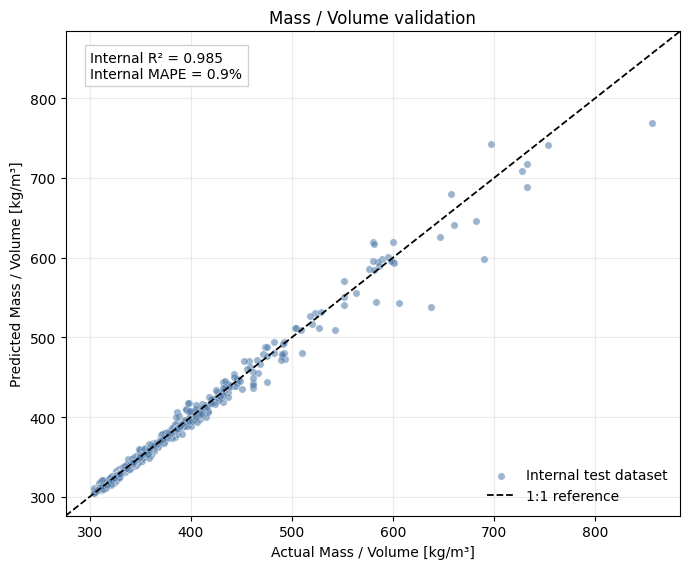

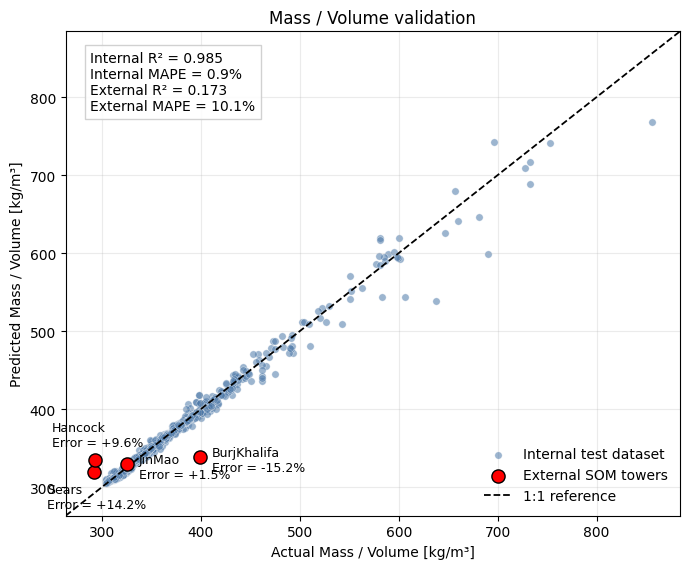

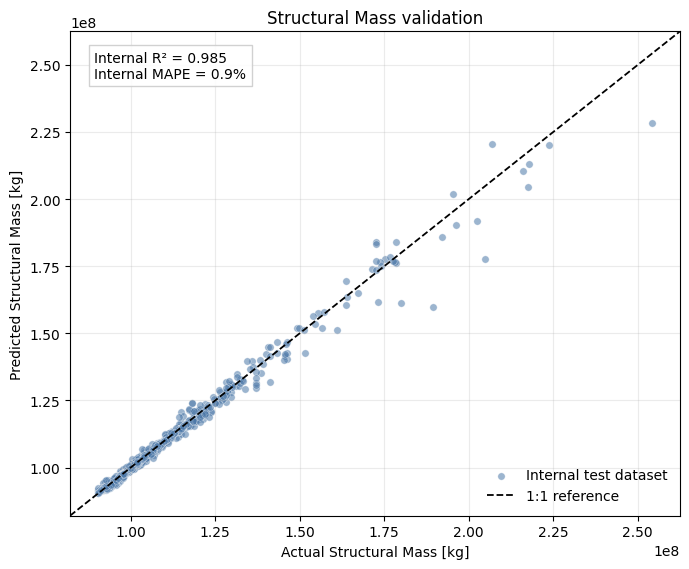

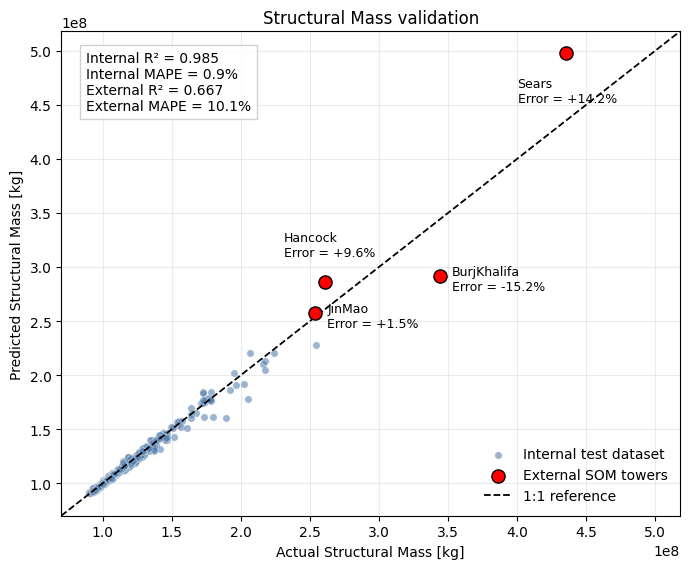

,Feature,Importance
0,Height,0.404726
1,Slenderness Ratio,0.212779
2,Plan Aspect Ratio,0.007002
3,Volumetric Convexity,0.014142
4,Surface-to-Volume Ratio,0.030297
5,Mean Compactness,0.265607
6,Volumetric Symmetry Score,0.000529
7,Plan Aspect Ratio Variation,0.000163
8,Max CoM,0.000201
9,Bulge Factor,0.000779


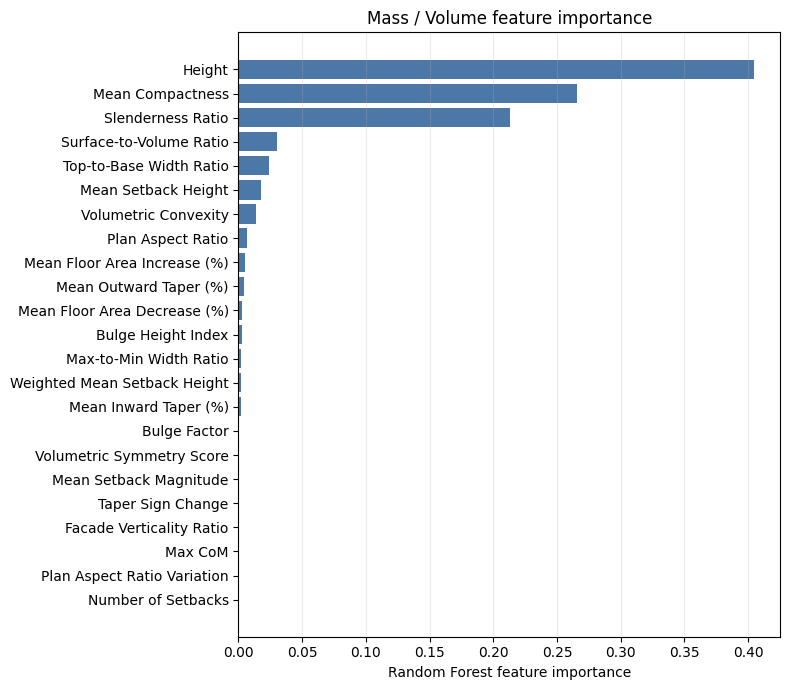

In [ ]:
def plot_validation(quantity, units, include_external=False):
    actual_column = f"Actual {quantity}"
    predicted_column = f"Predicted {quantity}"
    fig, ax = plt.subplots(figsize=(7.0, 5.8))
    ax.scatter(internal_results[actual_column], internal_results[predicted_column],
               s=28, alpha=0.55, color="#4C78A8", edgecolor="white", linewidth=0.4,
               label="Internal test dataset")
    values = [internal_results[actual_column], internal_results[predicted_column]]
    metrics = internal_mass_per_volume_metrics if quantity == "Mass / Volume" else internal_total_mass_metrics
    annotation = f"Internal R² = {metrics['R²']:.3f}\nInternal MAPE = {metrics['MAPE (%)']:.1f}%"
    if include_external:
        ax.scatter(external_results[actual_column], external_results[predicted_column],
                   s=90, color="red", edgecolor="black", zorder=10, label="External SOM towers")
        offsets = {"Hancock": (-30, 19), "JinMao": (9, -10), "BurjKhalifa": (9, -10), "Sears": (-35, -35)}
        for _, row in external_results.iterrows():
            ax.annotate(f"{row['Building ID']}\nError = {row['Percent Error (%)']:+.1f}%",
                        (row[actual_column], row[predicted_column]),
                        xytext=offsets.get(row['Building ID'], (8, 6)),
                        textcoords="offset points", fontsize=9)
        values.extend([external_results[actual_column], external_results[predicted_column]])
        external_metrics = external_mass_per_volume_metrics if quantity == "Mass / Volume" else external_total_mass_metrics
        annotation += f"\nExternal R² = {external_metrics['R²']:.3f}\nExternal MAPE = {external_metrics['MAPE (%)']:.1f}%"
    all_values = np.concatenate(values)
    padding = max(float(np.ptp(all_values)) * 0.05, 1.0)
    limits = (all_values.min() - padding, all_values.max() + padding)
    ax.plot(limits, limits, "k--", linewidth=1.3, label="1:1 reference")
    ax.set(xlim=limits, ylim=limits, xlabel=f"Actual {quantity} [{units}]",
           ylabel=f"Predicted {quantity} [{units}]", title=f"{quantity} validation")
    ax.text(0.04, 0.96, annotation, transform=ax.transAxes, va="top",
            bbox=dict(facecolor="white", edgecolor="#cccccc", alpha=0.9))
    ax.grid(True, alpha=0.25)
    ax.legend(loc="lower right", frameon=False)
    fig.tight_layout()
    if SAVE_OUTPUTS:
        prediction_results_folder.mkdir(parents=True, exist_ok=True)
        name = quantity.replace(" / ", "_per_").replace(" ", "_")
        fig.savefig(prediction_results_folder / f"{name}_{'combined' if include_external else 'internal'}.png", dpi=300)
    plt.show()

plot_validation("Mass / Volume", "kg/m³")
plot_validation("Mass / Volume", "kg/m³", include_external=True)
plot_validation("Structural Mass", "kg")
plot_validation("Structural Mass", "kg", include_external=True)

feature_importance = pd.DataFrame({
    "Feature": model_feature_columns,
    "Importance": structural_mass_model.feature_importances_,
})
display(feature_importance)
plot_importance = feature_importance.sort_values("Importance")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(plot_importance["Feature"], plot_importance["Importance"], color="#4C78A8")
ax.set(title="Mass / Volume feature importance", xlabel="Random Forest feature importance")
ax.grid(True, axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

## 11. Export trained model

Inputs to the exported estimator must already use the training preprocessing: in particular, Plan Aspect Ratio is the reciprocal of the raw CSV value. The standalone helper also accepts raw metrics explicitly and applies the preserved external preprocessing once. Metric Volume is supplied separately for optional total mass conversion.

In [ ]:
# ---------------------------------------------------
# EXPORT TRAINED MODEL
# ---------------------------------------------------
model_package = {
    "model": structural_mass_model,
    "feature_columns": model_feature_columns.copy(),
    "target": "Mass / Volume",
    "target_definition": "Structural Mass / Metric Volume",
    "target_units": "kg/m³",
    "model_type": "RandomForestRegressor",
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "joblib_version": joblib.__version__,
    "model_settings": model_settings.copy(),
    "resolved_model_settings": structural_mass_model.get_params(),
    "n_features": len(model_feature_columns),
    "training_rows": len(model_training_df),
    "fitted_rows": len(X_train),
    "test_rows": len(X_test),
    "split": {"test_size": 0.20, "random_state": 42},
    "preprocessing": {
        "input_space": "cleaned geometry metrics; preprocessing is not inside the estimator",
        "Plan Aspect Ratio": "1 / raw value; raw zero is invalid",
        "Setback Count": "use Number of Setbacks if Setback Count is absent",
        "no_setbacks": "missing Mean Setback Height and Weighted Mean Setback Height become 1.0 when Setback Count is zero (missing count treated as zero)",
        "other_metrics": "numeric, finite, original cleaned geometry definitions; Height and Slenderness Ratio unchanged",
    },
    "validation_metrics": {
        "internal_mass_per_volume": internal_mass_per_volume_metrics,
        "external_mass_per_volume": external_mass_per_volume_metrics,
        "internal_structural_mass": internal_total_mass_metrics,
        "external_structural_mass": external_total_mass_metrics,
    },
}
model_output_path = prediction_results_folder / "structural_mass_model.joblib"
model_output_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model_package, model_output_path, compress=3)
print(f"Saved trained model to: {model_output_path.resolve()}")

Saved trained model to: C:\Users\lilli\OneDrive\Desktop\Master Thesis\Grasshopper Data\MidJune\PredictionModelResults\structural_mass_model.joblib


## 12. Reload and verify exported model

In [ ]:
loaded_package = joblib.load(model_output_path)
loaded_model = loaded_package["model"]
loaded_features = loaded_package["feature_columns"]
assert loaded_features == model_feature_columns
original_prediction = structural_mass_model.predict(X_test.iloc[[0]])
loaded_prediction = loaded_model.predict(X_test.iloc[[0]][loaded_features])
np.testing.assert_allclose(original_prediction, loaded_prediction)
np.testing.assert_array_equal(original_prediction, loaded_prediction)
np.testing.assert_array_equal(
    predicted_mass_per_volume, loaded_model.predict(X_test[loaded_features])
)
np.testing.assert_array_equal(
    external_predicted_mass_per_volume, loaded_model.predict(external_X[loaded_features])
)
print("Saved model successfully reloaded. Prediction matches original trained model exactly.")

Saved model successfully reloaded. Prediction matches original trained model exactly.
